Saved DDL to: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\04_1_schema_ddl.sql

Source Rows: 968,294 | Columns: 12
                     Column   Dtype  Null_Count  Null_Pct
        Global_active_power float64         466    0.0481
      Global_reactive_power float64         466    0.0481
                    Voltage float64         466    0.0481
           Global_intensity float64         466    0.0481
             Sub_metering_1 float64         466    0.0481
             Sub_metering_2 float64         466    0.0481
             Sub_metering_3 float64         466    0.0481
              GAP_Indicator   int64           0    0.0000
Global_active_power_imputed float64           1    0.0001
       Outlier_Flag_Extreme   int64           0    0.0000
   Derived_Active_Energy_Wh float64         466    0.0481
    Sub_metering_4_Residual float64         466    0.0481


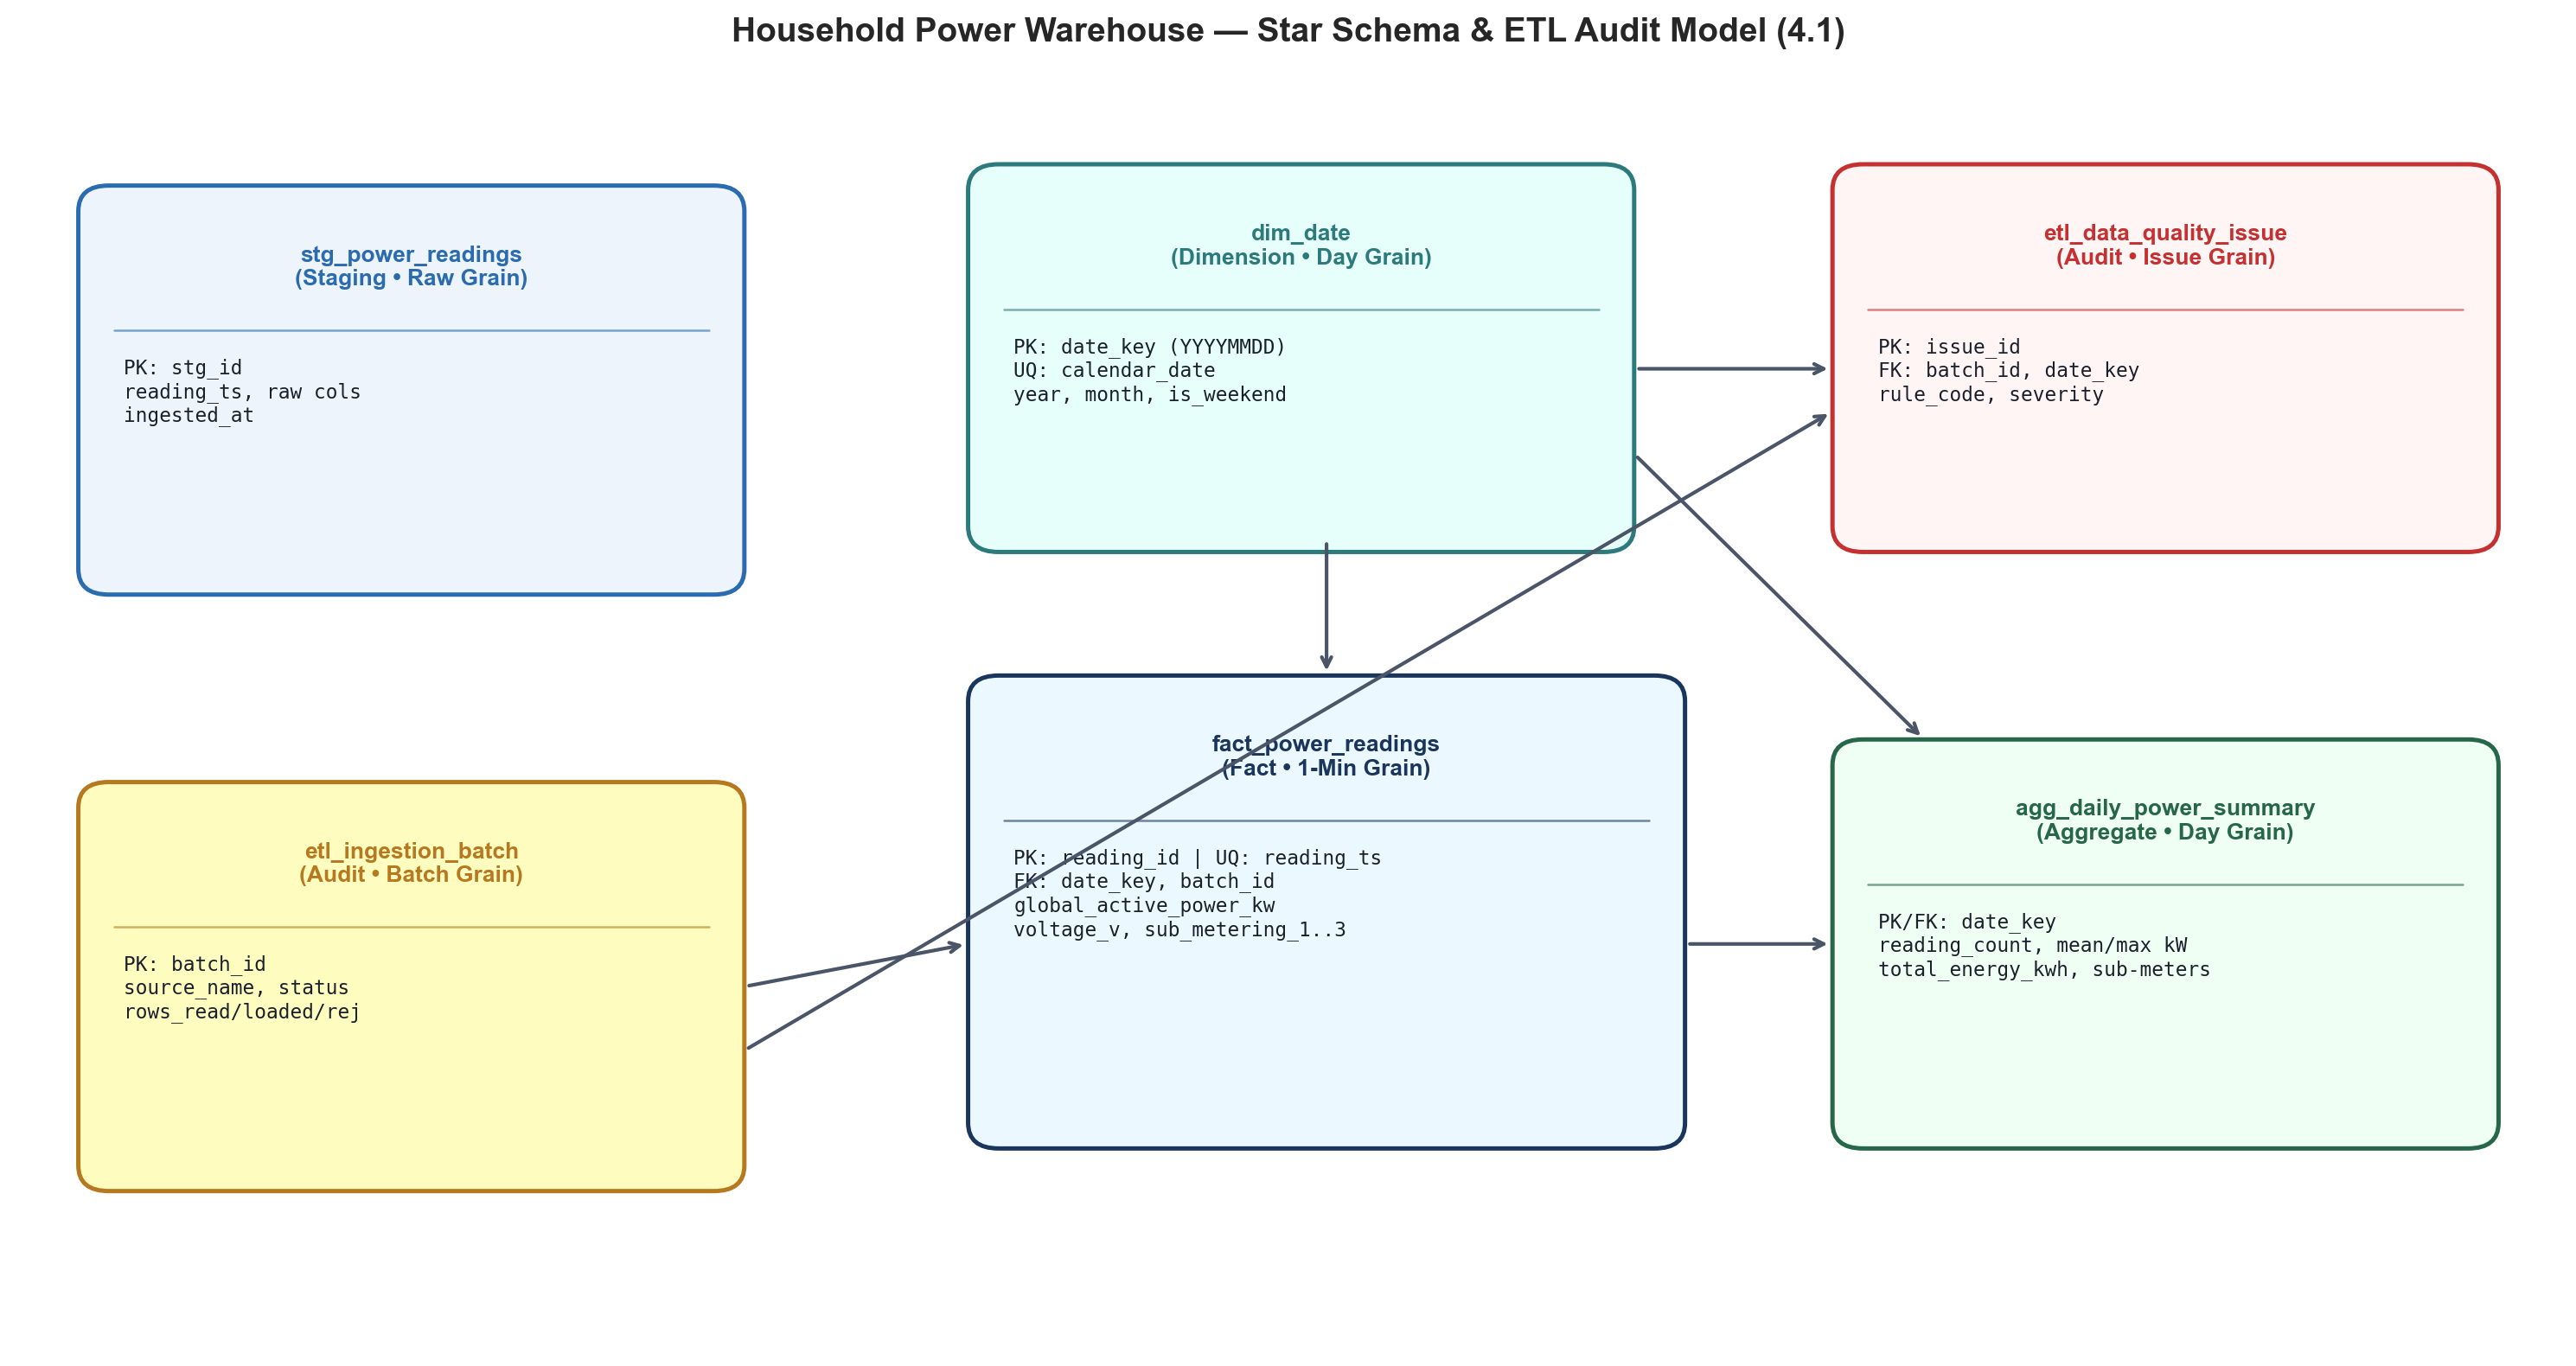

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PROJECT_ROOT = Path(
    r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
)
PARQUET_PATH = PROJECT_ROOT / "cleaned_household_power.parquet"

# --- 1. DDL Script (MySQL 8.0) ---
ddl_sql = """
CREATE DATABASE IF NOT EXISTS kenya_power_dw
  CHARACTER SET utf8mb4
  COLLATE utf8mb4_0900_ai_ci;
USE kenya_power_dw;

-- 1. Staging Table (Raw / Pre-Validation Landing)
CREATE TABLE IF NOT EXISTS stg_power_readings (
    stg_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    source_file VARCHAR(255) NOT NULL,
    raw_datetime_str VARCHAR(64) NOT NULL,
    reading_ts DATETIME NULL,
    global_active_power DOUBLE NULL,
    global_reactive_power DOUBLE NULL,
    voltage DOUBLE NULL,
    global_intensity DOUBLE NULL,
    sub_metering_1 DOUBLE NULL,
    sub_metering_2 DOUBLE NULL,
    sub_metering_3 DOUBLE NULL,
    ingested_at TIMESTAMP NOT NULL DEFAULT CURRENT_TIMESTAMP,
    KEY idx_stg_reading_ts (reading_ts)
);

-- 2. Ingestion Batch Control Table
CREATE TABLE IF NOT EXISTS etl_ingestion_batch (
    batch_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    source_name VARCHAR(255) NOT NULL,
    started_at DATETIME NOT NULL,
    finished_at DATETIME NULL,
    status VARCHAR(32) NOT NULL DEFAULT 'RUNNING',
    rows_read BIGINT UNSIGNED NOT NULL DEFAULT 0,
    rows_loaded BIGINT UNSIGNED NOT NULL DEFAULT 0,
    rows_rejected BIGINT UNSIGNED NOT NULL DEFAULT 0,
    CONSTRAINT chk_batch_status CHECK (status IN ('RUNNING', 'SUCCESS', 'FAILED', 'PARTIAL'))
);

-- 3. Calendar Date Dimension
CREATE TABLE IF NOT EXISTS dim_date (
    date_key INT UNSIGNED PRIMARY KEY,
    calendar_date DATE NOT NULL,
    year_num SMALLINT UNSIGNED NOT NULL,
    quarter_num TINYINT UNSIGNED NOT NULL,
    month_num TINYINT UNSIGNED NOT NULL,
    month_name VARCHAR(16) NOT NULL,
    day_of_month TINYINT UNSIGNED NOT NULL,
    day_of_week TINYINT UNSIGNED NOT NULL,
    day_name VARCHAR(16) NOT NULL,
    is_weekend TINYINT(1) NOT NULL,
    CONSTRAINT uq_dim_date UNIQUE (calendar_date),
    CONSTRAINT chk_is_weekend CHECK (is_weekend IN (0, 1))
);

-- 4. Fact Table: 1-Minute Household Power Readings
CREATE TABLE IF NOT EXISTS fact_power_readings (
    reading_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    reading_ts DATETIME NOT NULL,
    date_key INT UNSIGNED NOT NULL,
    batch_id BIGINT UNSIGNED NOT NULL,
    global_active_power_kw DECIMAL(10, 4) NOT NULL,
    global_reactive_power_kvar DECIMAL(10, 4) NULL,
    voltage_v DECIMAL(8, 3) NULL,
    global_intensity_a DECIMAL(8, 3) NULL,
    sub_metering_1_wh DECIMAL(10, 3) NULL,
    sub_metering_2_wh DECIMAL(10, 3) NULL,
    sub_metering_3_wh DECIMAL(10, 3) NULL,
    CONSTRAINT uq_fact_reading_ts UNIQUE (reading_ts),
    CONSTRAINT chk_active_power_nonneg CHECK (global_active_power_kw >= 0),
    CONSTRAINT chk_voltage_pos CHECK (voltage_v IS NULL OR voltage_v > 0),
    CONSTRAINT fk_fact_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key),
    CONSTRAINT fk_fact_batch FOREIGN KEY (batch_id) REFERENCES etl_ingestion_batch (batch_id),
    KEY idx_fact_date_ts (date_key, reading_ts),
    KEY idx_fact_batch (batch_id)
);

-- 5. Data Quality Issue Log
CREATE TABLE IF NOT EXISTS etl_data_quality_issue (
    issue_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    batch_id BIGINT UNSIGNED NOT NULL,
    date_key INT UNSIGNED NULL,
    reading_ts DATETIME NULL,
    column_name VARCHAR(64) NULL,
    rule_code VARCHAR(64) NOT NULL,
    severity VARCHAR(16) NOT NULL DEFAULT 'WARN',
    issue_detail VARCHAR(500) NULL,
    detected_at TIMESTAMP NOT NULL DEFAULT CURRENT_TIMESTAMP,
    CONSTRAINT chk_dq_severity CHECK (severity IN ('INFO', 'WARN', 'ERROR')),
    CONSTRAINT fk_dq_batch FOREIGN KEY (batch_id) REFERENCES etl_ingestion_batch (batch_id),
    CONSTRAINT fk_dq_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key),
    KEY idx_dq_batch_rule (batch_id, rule_code),
    KEY idx_dq_date (date_key)
);

-- 6. Daily Aggregate Table (One Row per Calendar Day)
CREATE TABLE IF NOT EXISTS agg_daily_power_summary (
    date_key INT UNSIGNED PRIMARY KEY,
    reading_count INT UNSIGNED NOT NULL,
    mean_active_power_kw DECIMAL(10, 4) NOT NULL,
    max_active_power_kw DECIMAL(10, 4) NOT NULL,
    total_energy_kwh DECIMAL(12, 4) NOT NULL,
    mean_voltage_v DECIMAL(8, 3) NULL,
    total_sub_meter_1_wh DECIMAL(12, 3) NULL,
    total_sub_meter_2_wh DECIMAL(12, 3) NULL,
    total_sub_meter_3_wh DECIMAL(12, 3) NULL,
    CONSTRAINT fk_agg_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key)
);
""".strip()

ddl_file = PROJECT_ROOT / "04_1_schema_ddl.sql"
ddl_file.write_text(ddl_sql, encoding="utf-8")
print(f"Saved DDL to: {ddl_file}")

# --- 2. Source Dataset Profile (Row Count & Nulls) ---
if PARQUET_PATH.exists():
    df_src = pd.read_parquet(PARQUET_PATH)
    null_profile = pd.DataFrame({
        "Column": df_src.columns,
        "Dtype": [str(df_src[c].dtype) for c in df_src.columns],
        "Null_Count": [int(df_src[c].isna().sum()) for c in df_src.columns],
        "Null_Pct": [round(float(df_src[c].isna().mean() * 100), 4) for c in df_src.columns],
    })
    print(f"\nSource Rows: {len(df_src):,} | Columns: {df_src.shape[1]}")
    print(null_profile.to_string(index=False))
else:
    print(f"\nParquet not found at {PARQUET_PATH}; skipped live row/null profile.")

# --- 3. Schema / ERD Diagram ---
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(figsize=(15, 8), dpi=200)
ax.set_xlim(0, 100)
ax.set_ylim(0, 60)
ax.axis("off")
ax.set_title("Household Power Warehouse — Star Schema & ETL Audit Model (4.1)", fontsize=14, fontweight="bold", pad=12)

tables = [
    ("stg_power_readings\n(Staging • Raw Grain)", 3, 36, 25, 18, "#eef4fb", "#2b6cb0",
     "PK: stg_id\nreading_ts, raw cols\ningested_at"),
    ("etl_ingestion_batch\n(Audit • Batch Grain)", 3, 8, 25, 18, "#fefcbf", "#b7791f",
     "PK: batch_id\nsource_name, status\nrows_read/loaded/rej"),
    ("dim_date\n(Dimension • Day Grain)", 38, 38, 25, 17, "#e6fffa", "#2c7a7b",
     "PK: date_key (YYYYMMDD)\nUQ: calendar_date\nyear, month, is_weekend"),
    ("fact_power_readings\n(Fact • 1-Min Grain)", 38, 10, 27, 21, "#ebf8ff", "#1a365d",
     "PK: reading_id | UQ: reading_ts\nFK: date_key, batch_id\nglobal_active_power_kw\nvoltage_v, sub_metering_1..3"),
    ("etl_data_quality_issue\n(Audit • Issue Grain)", 72, 38, 25, 17, "#fff5f5", "#c53030",
     "PK: issue_id\nFK: batch_id, date_key\nrule_code, severity"),
    ("agg_daily_power_summary\n(Aggregate • Day Grain)", 72, 10, 25, 18, "#f0fff4", "#276749",
     "PK/FK: date_key\nreading_count, mean/max kW\ntotal_energy_kwh, sub-meters"),
]

for title, x, y, w, h, fc, ec, body in tables:
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6,rounding_size=1.2",
                         facecolor=fc, edgecolor=ec, linewidth=1.8)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h - 2.2, title, ha="center", va="top", fontsize=9.5, fontweight="bold", color=ec)
    ax.plot([x + 0.8, x + w - 0.8], [y + h - 6.2, y + h - 6.2], color=ec, lw=0.9, alpha=0.6)
    ax.text(x + 1.2, y + h - 7.5, body, ha="left", va="top", fontsize=8.2, color="#1a202c", family="monospace")

# Relationship arrows
arrows = [
    ((51.5, 38), (51.5, 31.6)),   # dim_date -> fact_power_readings
    ((28.6, 17), (37.4, 19)),     # etl_ingestion_batch -> fact_power_readings
    ((28.6, 14), (71.4, 44)),     # etl_ingestion_batch -> etl_data_quality_issue
    ((63.6, 46), (71.4, 46)),     # dim_date -> etl_data_quality_issue
    ((65.6, 19), (71.4, 19)),     # fact_power_readings -> agg_daily_power_summary
    ((63.6, 42), (75.0, 28.6)),   # dim_date -> agg_daily_power_summary
]
for (x1, y1), (x2, y2) in arrows:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#4a5568", lw=1.5, shrinkA=2, shrinkB=2))

plt.tight_layout()
plt.show()

Saved SQL script to: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\04_2_cleaning_and_validation.sql

=== Q1 & Q4: Row, Timestamp & Date Uniqueness ===
 total_rows  unique_timestamps  unique_dates  duplicate_rows
     968294             968294           728               0

=== Q6: Duplicate Timestamps (Top 10 shown; 0 in sample) ===
No duplicate timestamps found.

=== Q1: Readings per Year & Month (First 12 rows) ===
  yr  mo  reading_count  active_days  mean_kw
2006  12          21820           16   1.9114
2007   1          43657           31   1.5711
2007   2          37821           28   1.4720
2007   3          41050           31   1.4040
2007   4          35913           29   0.9534
2007   5          43378           31   1.0070
2007   6          41726           30   0.8479
2007   7          41494           31   0.7055
2007   8          39655           31   0.8374
2007   9          40016           30   1.0307
2007  10          40270           

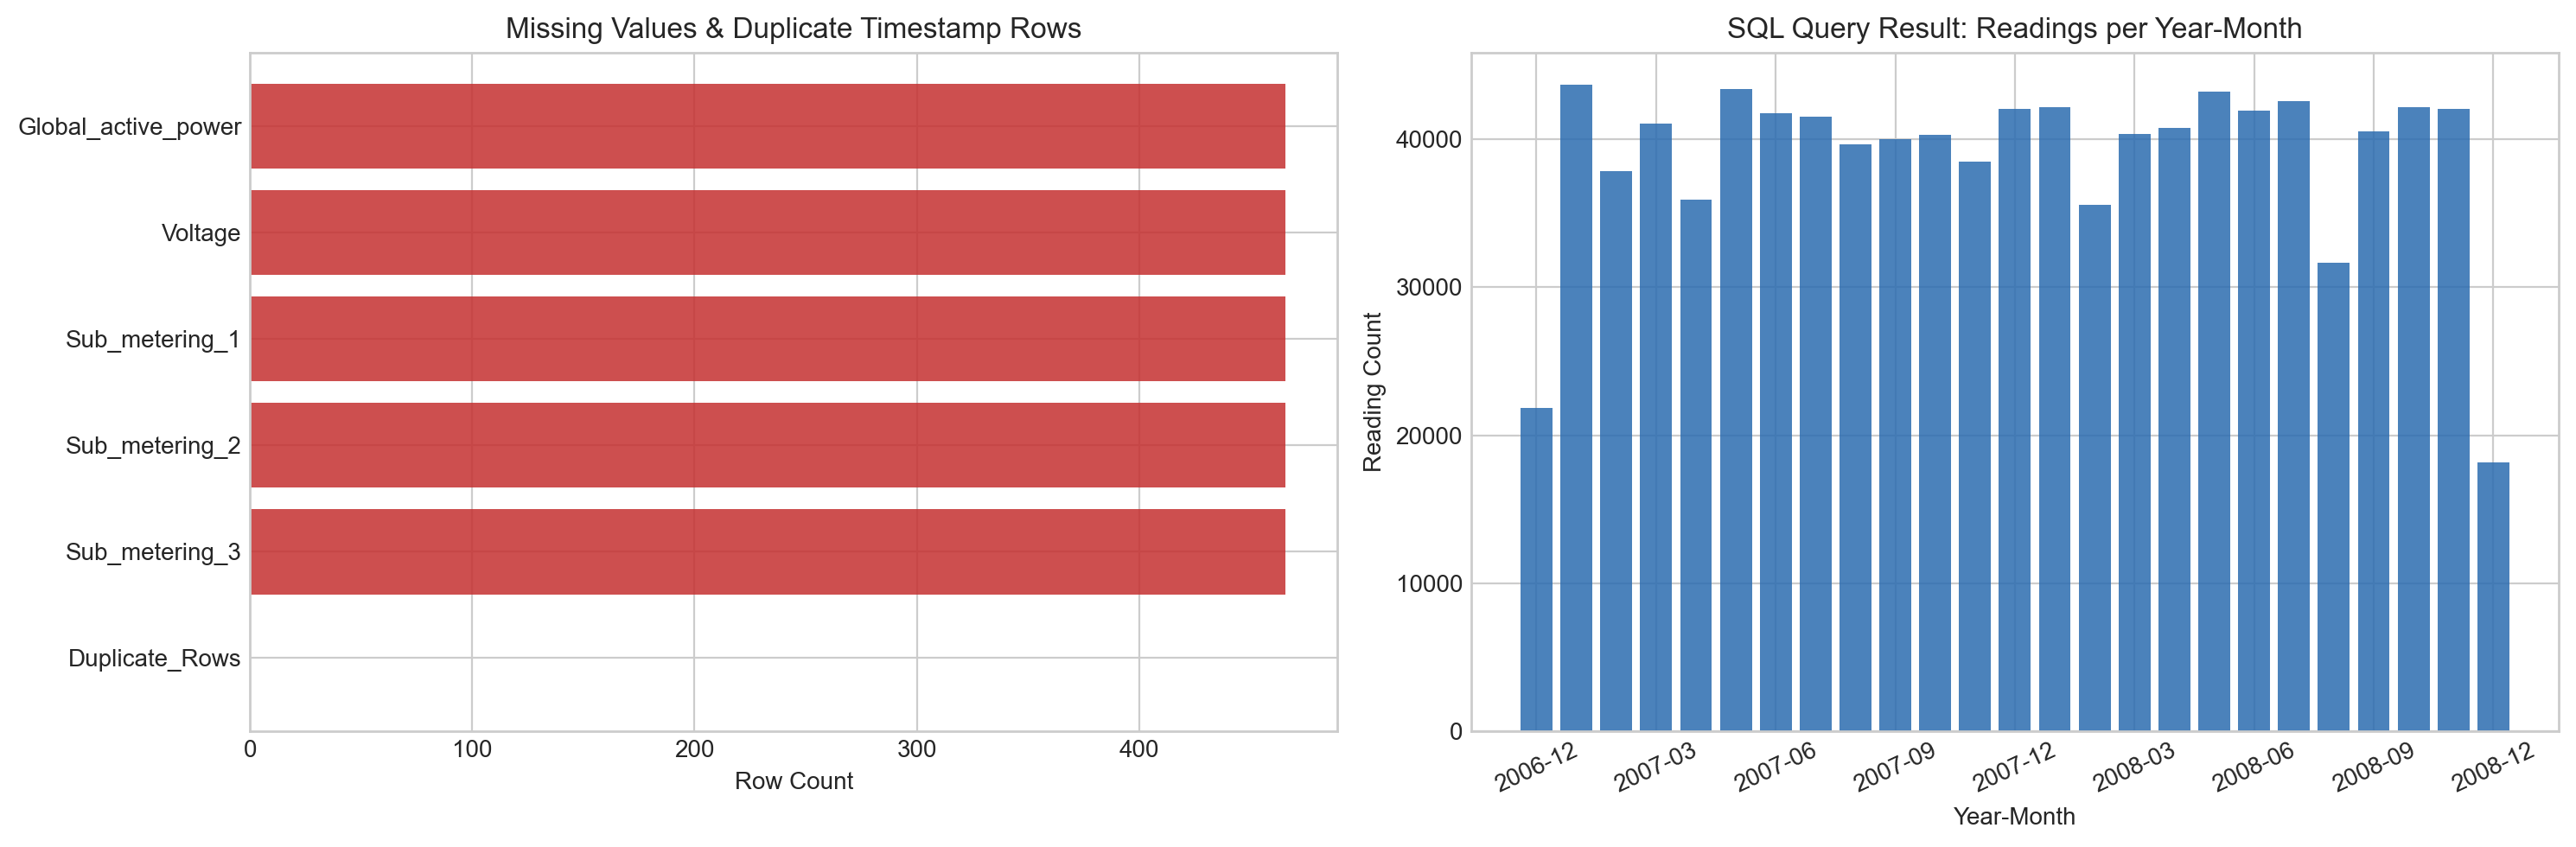

In [2]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
)
PARQUET_PATH = PROJECT_ROOT / "cleaned_household_power.parquet"

# --- 1. Save SQL Cleaning & Validation Script (MySQL 8.0) ---
sql_script = """
USE kenya_power_dw;

-- A. Unique timestamps, unique dates, and duplicate check via GROUP BY + HAVING
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT reading_ts) AS unique_timestamps,
    COUNT(DISTINCT DATE(reading_ts)) AS unique_dates,
    COUNT(*) - COUNT(DISTINCT reading_ts) AS duplicate_timestamp_rows
FROM stg_power_readings;

SELECT
    reading_ts,
    COUNT(*) AS occurrence_count
FROM stg_power_readings
WHERE reading_ts IS NOT NULL
GROUP BY reading_ts
HAVING COUNT(*) > 1
ORDER BY occurrence_count DESC, reading_ts;

-- B. Readings per year and month
SELECT
    YEAR(reading_ts) AS yr,
    MONTH(reading_ts) AS mo,
    COUNT(*) AS reading_count,
    COUNT(DISTINCT DATE(reading_ts)) AS active_days,
    ROUND(AVG(global_active_power), 4) AS mean_active_power_kw
FROM stg_power_readings
WHERE reading_ts IS NOT NULL
GROUP BY YEAR(reading_ts), MONTH(reading_ts)
ORDER BY yr, mo;

-- C. Missing or invalid measurements
SELECT
    reading_ts,
    global_active_power,
    voltage,
    global_intensity,
    sub_metering_1,
    sub_metering_2,
    sub_metering_3,
    CASE
        WHEN reading_ts IS NULL THEN 'MISSING_TIMESTAMP'
        WHEN global_active_power IS NULL THEN 'MISSING_ACTIVE_POWER'
        WHEN global_active_power < 0 THEN 'NEGATIVE_ACTIVE_POWER'
        WHEN voltage IS NOT NULL AND voltage <= 0 THEN 'NON_POSITIVE_VOLTAGE'
        WHEN sub_metering_1 < 0 OR sub_metering_2 < 0 OR sub_metering_3 < 0 THEN 'NEGATIVE_SUBMETER'
        ELSE 'VALID'
    END AS validation_status
FROM stg_power_readings
WHERE reading_ts IS NULL
   OR global_active_power IS NULL
   OR global_active_power < 0
   OR (voltage IS NOT NULL AND voltage <= 0)
   OR COALESCE(sub_metering_1, 0) < 0
   OR COALESCE(sub_metering_2, 0) < 0
   OR COALESCE(sub_metering_3, 0) < 0
ORDER BY reading_ts
LIMIT 500;

-- D. Days exceeding a chosen peak threshold (e.g., max active power > 6.0 kW)
SELECT
    DATE(reading_ts) AS reading_date,
    COUNT(*) AS n_readings,
    ROUND(AVG(global_active_power), 4) AS mean_kw,
    ROUND(MAX(global_active_power), 4) AS peak_kw
FROM stg_power_readings
WHERE global_active_power IS NOT NULL
GROUP BY DATE(reading_ts)
HAVING MAX(global_active_power) > 6.0
ORDER BY peak_kw DESC, reading_date;

-- E. Standardise, validate, and promote inside a safe transaction
START TRANSACTION;

INSERT IGNORE INTO fact_power_readings (
    reading_ts,
    date_key,
    batch_id,
    global_active_power_kw,
    global_reactive_power_kvar,
    voltage_v,
    global_intensity_a,
    sub_metering_1_wh,
    sub_metering_2_wh,
    sub_metering_3_wh
)
SELECT
    CAST(reading_ts AS DATETIME) AS reading_ts,
    CAST(DATE_FORMAT(reading_ts, '%Y%m%d') AS UNSIGNED) AS date_key,
    1 AS batch_id,
    CAST(COALESCE(NULLIF(TRIM(CAST(global_active_power AS CHAR)), ''), 0) AS DECIMAL(10, 4)) AS global_active_power_kw,
    CAST(global_reactive_power AS DECIMAL(10, 4)),
    CAST(voltage AS DECIMAL(8, 3)),
    CAST(global_intensity AS DECIMAL(8, 3)),
    CAST(sub_metering_1 AS DECIMAL(10, 3)),
    CAST(sub_metering_2 AS DECIMAL(10, 3)),
    CAST(sub_metering_3 AS DECIMAL(10, 3))
FROM stg_power_readings
WHERE reading_ts IS NOT NULL
  AND global_active_power IS NOT NULL
  AND global_active_power >= 0;

COMMIT;
""".strip()

sql_path = PROJECT_ROOT / "04_2_cleaning_and_validation.sql"
sql_path.write_text(sql_script, encoding="utf-8")
print(f"Saved SQL script to: {sql_path}")

# --- 2. Execute SQL Queries via SQLite on Source Data ---
df_raw = pd.read_parquet(PARQUET_PATH)
if isinstance(df_raw.index, pd.DatetimeIndex):
    df_sql = df_raw.reset_index().rename(columns={df_raw.index.name or "index": "reading_ts"})
elif "datetime" in df_sql.columns if "df_sql" in locals() else False:
    df_sql = df_raw.rename(columns={"datetime": "reading_ts"})
else:
    df_sql = df_raw.copy()
    if "reading_ts" not in df_sql.columns:
        df_sql["reading_ts"] = pd.to_datetime(df_sql.index, errors="coerce")

df_sql["reading_ts_str"] = pd.to_datetime(df_sql["reading_ts"], errors="coerce").dt.strftime("%Y-%m-%d %H:%M:%S")
df_sql["reading_date_str"] = pd.to_datetime(df_sql["reading_ts"], errors="coerce").dt.strftime("%Y-%m-%d")
df_sql["yr"] = pd.to_datetime(df_sql["reading_ts"], errors="coerce").dt.year
df_sql["mo"] = pd.to_datetime(df_sql["reading_ts"], errors="coerce").dt.month

power_c = next((c for c in ["Global_active_power", "global_active_power"] if c in df_sql.columns), None)
volt_c = next((c for c in ["Voltage", "voltage"] if c in df_sql.columns), None)
sub1_c = next((c for c in ["Sub_metering_1", "sub_metering_1"] if c in df_sql.columns), None)
sub2_c = next((c for c in ["Sub_metering_2", "sub_metering_2"] if c in df_sql.columns), None)
sub3_c = next((c for c in ["Sub_metering_3", "sub_metering_3"] if c in df_sql.columns), None)

conn = sqlite3.connect(":memory:")
keep_cols = ["reading_ts_str", "reading_date_str", "yr", "mo"] + [
    c for c in [power_c, volt_c, sub1_c, sub2_c, sub3_c] if c is not None
]
df_sql[keep_cols].to_sql("stg_power_readings", conn, index=False, if_exists="replace")

# Q1 & Q4: Unique timestamps, unique dates, duplicates
q_uniq = pd.read_sql_query(f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT reading_ts_str) AS unique_timestamps,
        COUNT(DISTINCT reading_date_str) AS unique_dates,
        COUNT(*) - COUNT(DISTINCT reading_ts_str) AS duplicate_rows
    FROM stg_power_readings
""", conn)
print("\n=== Q1 & Q4: Row, Timestamp & Date Uniqueness ===")
print(q_uniq.to_string(index=False))

# Q6: Duplicate timestamps via GROUP BY + HAVING
q_dups = pd.read_sql_query("""
    SELECT reading_ts_str AS reading_ts, COUNT(*) AS dup_count
    FROM stg_power_readings
    WHERE reading_ts_str IS NOT NULL
    GROUP BY reading_ts_str
    HAVING COUNT(*) > 1
    ORDER BY dup_count DESC
    LIMIT 10
""", conn)
print(f"\n=== Q6: Duplicate Timestamps (Top 10 shown; {len(q_dups)} in sample) ===")
print(q_dups.to_string(index=False) if len(q_dups) > 0 else "No duplicate timestamps found.")

# Q1: Readings per year and month
q_ym = pd.read_sql_query(f"""
    SELECT
        CAST(yr AS INT) AS yr,
        CAST(mo AS INT) AS mo,
        COUNT(*) AS reading_count,
        COUNT(DISTINCT reading_date_str) AS active_days,
        ROUND(AVG("{power_c}"), 4) AS mean_kw
    FROM stg_power_readings
    WHERE reading_ts_str IS NOT NULL
    GROUP BY yr, mo
    ORDER BY yr, mo
""", conn)
print("\n=== Q1: Readings per Year & Month (First 12 rows) ===")
print(q_ym.head(12).to_string(index=False))

# Q2: Missing or invalid measurements count
invalid_conds = []
if power_c:
    invalid_conds.append(f'"{power_c}" IS NULL OR "{power_c}" < 0')
if volt_c:
    invalid_conds.append(f'("{volt_c}" IS NOT NULL AND "{volt_c}" <= 0)')
for sc in [sub1_c, sub2_c, sub3_c]:
    if sc:
        invalid_conds.append(f'COALESCE("{sc}", 0) < 0')

where_inv = " OR ".join(invalid_conds) if invalid_conds else "1=0"
q_inv_cnt = pd.read_sql_query(f"""
    SELECT
        COUNT(*) AS invalid_or_missing_rows,
        SUM(CASE WHEN "{power_c}" IS NULL THEN 1 ELSE 0 END) AS null_power_rows,
        SUM(CASE WHEN "{power_c}" < 0 THEN 1 ELSE 0 END) AS neg_power_rows
    FROM stg_power_readings
    WHERE {where_inv}
""", conn)
print("\n=== Q2: Missing or Invalid Measurement Counts ===")
print(q_inv_cnt.to_string(index=False))

# Q3: Days exceeding peak threshold (> 6.0 kW)
q_peak_days = pd.read_sql_query(f"""
    SELECT
        reading_date_str AS reading_date,
        COUNT(*) AS n_readings,
        ROUND(AVG("{power_c}"), 4) AS mean_kw,
        ROUND(MAX("{power_c}"), 4) AS peak_kw
    FROM stg_power_readings
    WHERE "{power_c}" IS NOT NULL
    GROUP BY reading_date_str
    HAVING MAX("{power_c}") > 6.0
    ORDER BY peak_kw DESC
    LIMIT 10
""", conn)
print("\n=== Q3: Top Days Exceeding Peak Threshold (MAX > 6.0 kW) ===")
print(q_peak_days.to_string(index=False))

conn.close()

# --- 3. Visual Evidence: Null/Duplicate Chart & SQL Result Plots ---
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

# Left: Null counts per column + duplicate timestamp row count
check_cols = [c for c in [power_c, volt_c, sub1_c, sub2_c, sub3_c] if c is not None]
null_counts = [int(df_sql[c].isna().sum()) for c in check_cols] + [int(q_dups["dup_count"].sum() - len(q_dups)) if len(q_dups) > 0 else 0]
labels_left = check_cols + ["Duplicate_Rows"]
axes[0].barh(labels_left, null_counts, color="#c53030", alpha=0.85)
axes[0].set_title("Missing Values & Duplicate Timestamp Rows")
axes[0].set_xlabel("Row Count")
axes[0].invert_yaxis()

# Right: Monthly reading counts across timeline
ym_labels = [f"{int(r.yr)}-{int(r.mo):02d}" for r in q_ym.itertuples()]
axes[1].bar(range(len(q_ym)), q_ym["reading_count"], color="#2b6cb0", alpha=0.85)
axes[1].set_title("SQL Query Result: Readings per Year-Month")
axes[1].set_xlabel("Year-Month")
axes[1].set_ylabel("Reading Count")
step = max(1, len(ym_labels) // 8)
axes[1].set_xticks(range(0, len(ym_labels), step))
axes[1].set_xticklabels([ym_labels[i] for i in range(0, len(ym_labels), step)], rotation=25)

plt.tight_layout()
plt.show()

Saved MySQL query bank to: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\04_3_analytical_query_bank.sql
=== Monthly Average, Peak, Total kWh & Variability ===
 year_num  month_num  days_cnt  mean_kw  max_kw  total_kwh  range_kw  std_kw
     2006         12        16   1.9616   9.132     694.98     8.938  1.4173
     2007          1        31   1.5688   9.272    1143.14     9.074  1.2929
     2007          2        28   1.4258   9.410     927.85     9.206  1.3214
     2007          3        31   1.3744  10.670     960.55    10.470  1.2907
     2007          4        29   0.9357   8.160     568.71     8.056  1.0149
     2007          5        31   1.0062   7.672     728.06     7.566  1.0123
     2007          6        30   0.8464   7.614     589.04     7.532  0.9618
     2007          7        31   0.7017   7.240     486.34     7.142  0.8401
     2007          8        31   0.8335   8.694     553.17     8.596  0.9221
     2007          9        30  

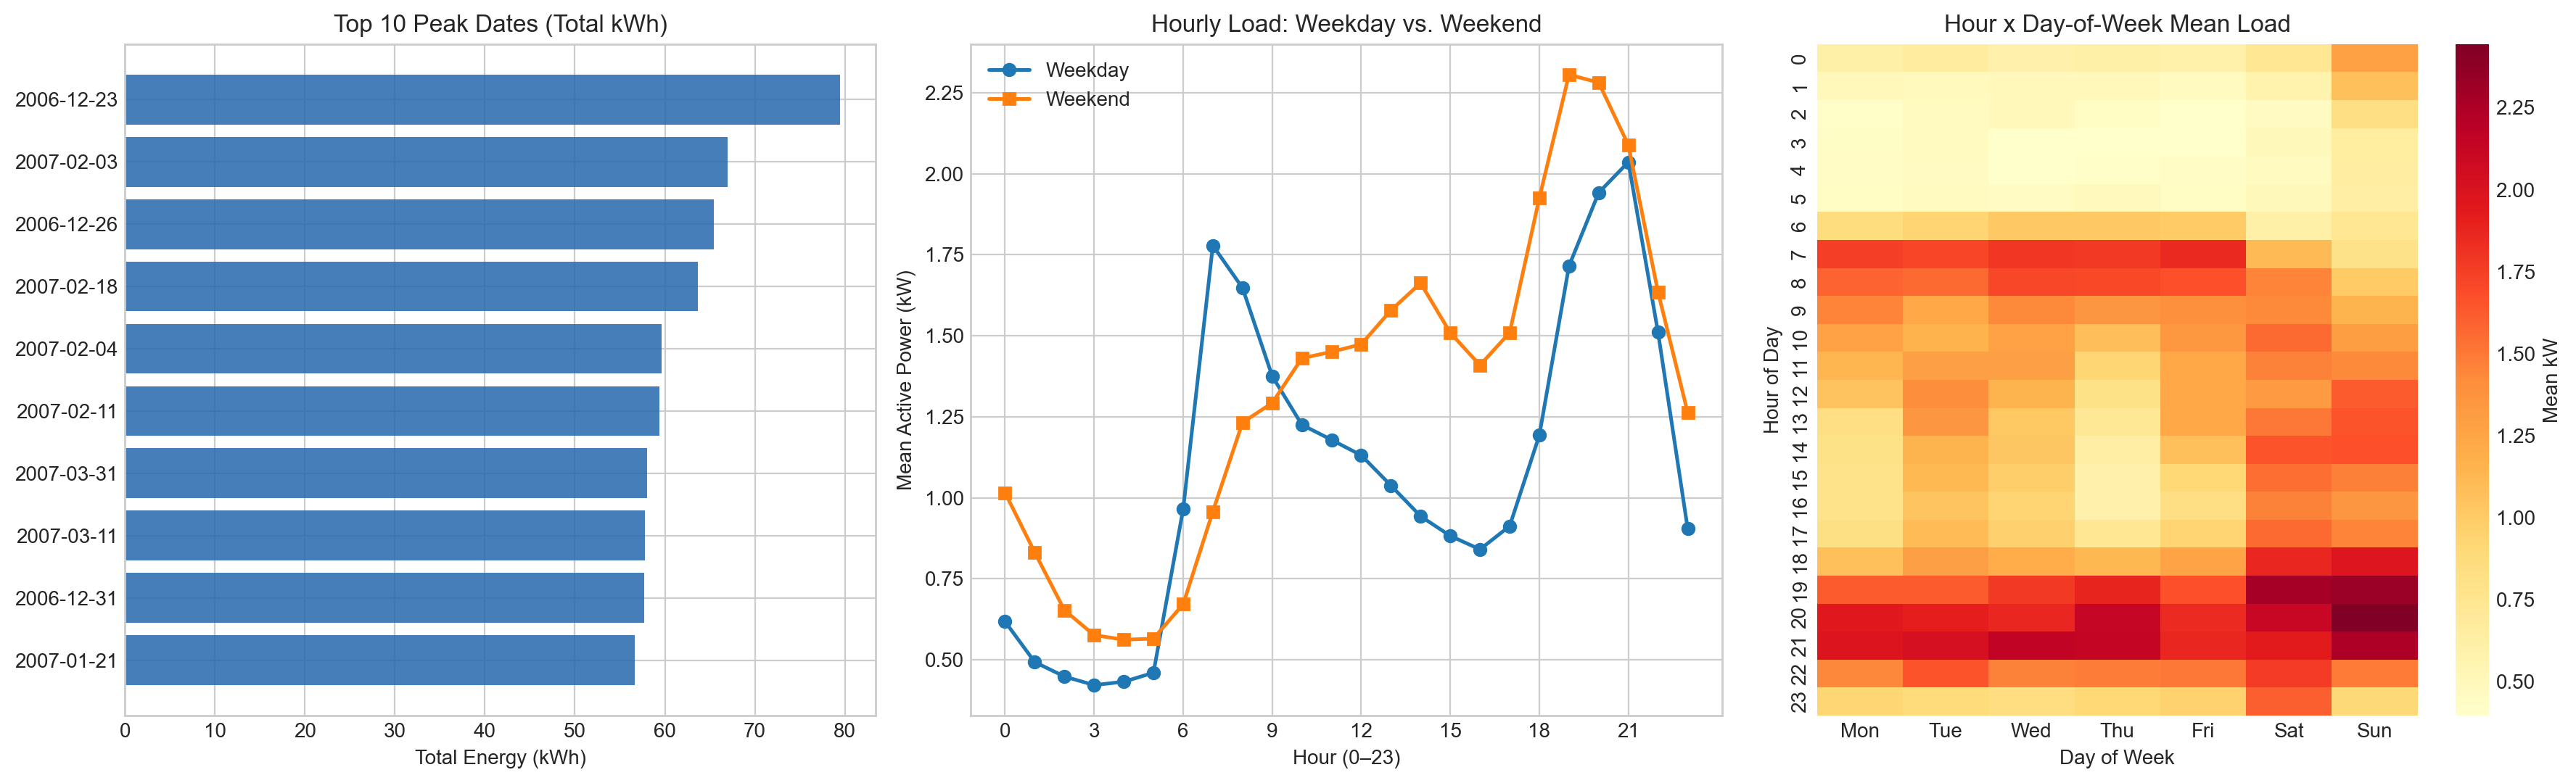

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(
    r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
)
PARQUET_PATH = PROJECT_ROOT / "cleaned_household_power.parquet"

# --- 1. Save Documented MySQL Query Bank (CTEs, Joins, Anti-Joins, Views, Conditional Agg) ---
mysql_query_bank = """
USE kenya_power_dw;

-- View: Daily Telemetry Summary
CREATE OR REPLACE VIEW v_daily_power_summary AS
SELECT
    d.date_key,
    d.calendar_date,
    d.year_num,
    d.month_num,
    d.day_name,
    d.is_weekend,
    COUNT(*) AS n_readings,
    ROUND(AVG(f.global_active_power_kw), 4) AS avg_kw,
    ROUND(MAX(f.global_active_power_kw), 4) AS peak_kw,
    ROUND(SUM(f.global_active_power_kw) / 60.0, 2) AS total_kwh
FROM fact_power_readings f
INNER JOIN dim_date d ON f.date_key = d.date_key
GROUP BY d.date_key, d.calendar_date, d.year_num, d.month_num, d.day_name, d.is_weekend;

-- 1. Monthly Average, Peak, and Total Energy from Daily CTE
WITH daily_energy AS (
    SELECT * FROM v_daily_power_summary
)
SELECT
    year_num,
    month_num,
    COUNT(*) AS active_days,
    ROUND(AVG(avg_kw), 4) AS mean_daily_kw,
    ROUND(MAX(peak_kw), 4) AS max_kw,
    ROUND(SUM(total_kwh), 2) AS total_monthly_kwh
FROM daily_energy
GROUP BY year_num, month_num
ORDER BY year_num, month_num;

-- 2. Top 10 Peak-Consumption Dates by Total Daily kWh
SELECT calendar_date, day_name, n_readings, peak_kw, total_kwh
FROM v_daily_power_summary
ORDER BY total_kwh DESC
LIMIT 10;

-- 3. Hours Above Threshold (> 1.50 kW) with Conditional Weekday/Weekend Averages
SELECT
    HOUR(f.reading_ts) AS hour_of_day,
    COUNT(*) AS n_readings,
    ROUND(AVG(f.global_active_power_kw), 4) AS avg_kw,
    ROUND(AVG(CASE WHEN d.is_weekend = 0 THEN f.global_active_power_kw END), 4) AS weekday_avg_kw,
    ROUND(AVG(CASE WHEN d.is_weekend = 1 THEN f.global_active_power_kw END), 4) AS weekend_avg_kw
FROM fact_power_readings f
INNER JOIN dim_date d ON f.date_key = d.date_key
GROUP BY HOUR(f.reading_ts)
HAVING AVG(f.global_active_power_kw) > 1.50
ORDER BY avg_kw DESC;

-- 4. Calendar Anti-Join: Dates with No Readings
SELECT d.calendar_date, d.day_name, d.is_weekend
FROM dim_date d
LEFT JOIN fact_power_readings f ON d.date_key = f.date_key
WHERE f.date_key IS NULL
ORDER BY d.calendar_date;

-- 5. Unmatched Dimension / Batch Check via NOT EXISTS
SELECT f.reading_id, f.reading_ts, f.date_key, f.batch_id
FROM fact_power_readings f
WHERE NOT EXISTS (SELECT 1 FROM dim_date d WHERE d.date_key = f.date_key)
   OR NOT EXISTS (SELECT 1 FROM etl_ingestion_batch b WHERE b.batch_id = f.batch_id);

-- 6. Sub-Meter Share of Total Active Energy (%)
WITH energy_totals AS (
    SELECT
        SUM(COALESCE(sub_metering_1_wh, 0)) / 1000.0 AS sm1_kwh,
        SUM(COALESCE(sub_metering_2_wh, 0)) / 1000.0 AS sm2_kwh,
        SUM(COALESCE(sub_metering_3_wh, 0)) / 1000.0 AS sm3_kwh,
        SUM(global_active_power_kw) / 60.0 AS total_kwh
    FROM fact_power_readings
)
SELECT
    ROUND(100.0 * sm1_kwh / NULLIF(total_kwh, 0), 2) AS sm1_pct,
    ROUND(100.0 * sm2_kwh / NULLIF(total_kwh, 0), 2) AS sm2_pct,
    ROUND(100.0 * sm3_kwh / NULLIF(total_kwh, 0), 2) AS sm3_pct,
    ROUND(100.0 * (total_kwh - (sm1_kwh + sm2_kwh + sm3_kwh)) / NULLIF(total_kwh, 0), 2) AS unmetered_pct
FROM energy_totals;
""".strip()

qbank_file = PROJECT_ROOT / "04_3_analytical_query_bank.sql"
qbank_file.write_text(mysql_query_bank, encoding="utf-8")
print(f"Saved MySQL query bank to: {qbank_file}")

# --- 2. Execute Analytical Queries in SQLite Memory ---
df_src = pd.read_parquet(PARQUET_PATH)
if isinstance(df_src.index, pd.DatetimeIndex):
    df_t = df_src.reset_index().rename(columns={df_src.index.name or "index": "reading_ts"})
elif "datetime" in df_src.columns:
    df_t = df_src.rename(columns={"datetime": "reading_ts"})
else:
    df_t = df_src.copy()
    df_t["reading_ts"] = pd.to_datetime(df_t.index, errors="coerce")

df_t["reading_ts"] = pd.to_datetime(df_t["reading_ts"], errors="coerce")
df_t = df_t.dropna(subset=["reading_ts"]).copy()

power_c = next((c for c in ["Global_active_power", "global_active_power"] if c in df_t.columns), None)
sm1_c = next((c for c in ["Sub_metering_1", "sub_metering_1"] if c in df_t.columns), None)
sm2_c = next((c for c in ["Sub_metering_2", "sub_metering_2"] if c in df_t.columns), None)
sm3_c = next((c for c in ["Sub_metering_3", "sub_metering_3"] if c in df_t.columns), None)

df_t["date_key"] = df_t["reading_ts"].dt.strftime("%Y%m%d").astype(int)
df_t["year_num"] = df_t["reading_ts"].dt.year.astype(int)
df_t["month_num"] = df_t["reading_ts"].dt.month.astype(int)
df_t["day_of_week"] = df_t["reading_ts"].dt.dayofweek.astype(int)
df_t["day_name"] = df_t["reading_ts"].dt.day_name()
df_t["is_weekend"] = df_t["reading_ts"].dt.dayofweek.isin([5, 6]).astype(int)
df_t["hour_of_day"] = df_t["reading_ts"].dt.hour.astype(int)
df_t["batch_id"] = 1

conn = sqlite3.connect(":memory:")

cal_idx = pd.date_range(df_t["reading_ts"].min().normalize(), df_t["reading_ts"].max().normalize(), freq="D")
pd.DataFrame({
    "date_key": cal_idx.strftime("%Y%m%d").astype(int),
    "calendar_date": cal_idx.strftime("%Y-%m-%d"),
    "year_num": cal_idx.year.astype(int),
    "month_num": cal_idx.month.astype(int),
    "day_name": cal_idx.day_name(),
    "is_weekend": cal_idx.dayofweek.isin([5, 6]).astype(int),
}).to_sql("dim_date", conn, index=False, if_exists="replace")

pd.DataFrame([{"batch_id": 1, "status": "SUCCESS"}]).to_sql("etl_ingestion_batch", conn, index=False, if_exists="replace")

f_cols = ["date_key", "batch_id", "hour_of_day", "day_of_week", power_c] + [
    c for c in [sm1_c, sm2_c, sm3_c] if c is not None
]
f_df = df_t[f_cols].rename(columns={
    power_c: "power_kw",
    **({sm1_c: "sm1_wh"} if sm1_c else {}),
    **({sm2_c: "sm2_wh"} if sm2_c else {}),
    **({sm3_c: "sm3_wh"} if sm3_c else {}),
}).dropna(subset=["power_kw"])
f_df.to_sql("fact_power_readings", conn, index=False, if_exists="replace")

# Monthly summary + variability
q_mon = pd.read_sql_query("""
    WITH daily_agg AS (
        SELECT
            d.calendar_date,
            d.year_num,
            d.month_num,
            COUNT(*) AS n_min,
            AVG(f.power_kw) AS avg_kw,
            MAX(f.power_kw) AS peak_kw,
            MIN(f.power_kw) AS min_kw,
            SUM(f.power_kw) / 60.0 AS day_kwh
        FROM fact_power_readings f
        INNER JOIN dim_date d ON f.date_key = d.date_key
        GROUP BY d.calendar_date, d.year_num, d.month_num
    )
    SELECT
        year_num,
        month_num,
        COUNT(*) AS days_cnt,
        ROUND(AVG(avg_kw), 4) AS mean_kw,
        ROUND(MAX(peak_kw), 4) AS max_kw,
        ROUND(SUM(day_kwh), 2) AS total_kwh,
        ROUND(MAX(peak_kw) - MIN(min_kw), 4) AS range_kw
    FROM daily_agg
    GROUP BY year_num, month_num
    ORDER BY year_num, month_num
""", conn)

ym_std = (
    df_t.dropna(subset=[power_c])
    .groupby(["year_num", "month_num"])[power_c]
    .std(ddof=1)
    .reset_index(name="std_kw")
)
q_mon = q_mon.merge(ym_std, on=["year_num", "month_num"])
print("=== Monthly Average, Peak, Total kWh & Variability ===")
print(q_mon.round(4).to_string(index=False))

# Top 10 peak dates
q_top10 = pd.read_sql_query("""
    SELECT
        d.calendar_date,
        d.day_name,
        COUNT(*) AS n_readings,
        ROUND(MAX(f.power_kw), 4) AS peak_kw,
        ROUND(SUM(f.power_kw) / 60.0, 2) AS total_kwh
    FROM fact_power_readings f
    INNER JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY d.calendar_date, d.day_name
    ORDER BY total_kwh DESC
    LIMIT 10
""", conn)
print("\n=== Top 10 Peak Dates (Total kWh) ===")
print(q_top10.to_string(index=False))

# Hours > 1.50 kW
q_hrs_gt = pd.read_sql_query("""
    SELECT
        f.hour_of_day,
        ROUND(AVG(f.power_kw), 4) AS avg_kw,
        ROUND(AVG(CASE WHEN d.is_weekend = 0 THEN f.power_kw END), 4) AS weekday_kw,
        ROUND(AVG(CASE WHEN d.is_weekend = 1 THEN f.power_kw END), 4) AS weekend_kw
    FROM fact_power_readings f
    INNER JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY f.hour_of_day
    HAVING AVG(f.power_kw) > 1.50
    ORDER BY avg_kw DESC
""", conn)
print("\n=== Hours with Avg Active Power > 1.50 kW ===")
print(q_hrs_gt.to_string(index=False))

# Missing dates & unmatched rows
miss_cnt = pd.read_sql_query("""
    SELECT COUNT(*) AS missing_dates
    FROM dim_date d
    LEFT JOIN fact_power_readings f ON d.date_key = f.date_key
    WHERE f.date_key IS NULL
""", conn)["missing_dates"].iloc[0]

orphan_cnt = pd.read_sql_query("""
    SELECT COUNT(*) AS orphan_rows
    FROM fact_power_readings f
    WHERE NOT EXISTS (SELECT 1 FROM dim_date d WHERE d.date_key = f.date_key)
       OR NOT EXISTS (SELECT 1 FROM etl_ingestion_batch b WHERE b.batch_id = f.batch_id)
""", conn)["orphan_rows"].iloc[0]
print(f"\nMissing calendar dates: {int(miss_cnt)} | Unmatched fact rows: {int(orphan_cnt)}")

# Sub-meter shares
sm_parts = [f"SUM(COALESCE({c}, 0)) / 1000.0 AS {lbl}_kwh" for c, lbl in [("sm1_wh", "SM1"), ("sm2_wh", "SM2"), ("sm3_wh", "SM3")] if c in f_df.columns]
q_sm = pd.read_sql_query(f"SELECT {', '.join(sm_parts)}, SUM(power_kw) / 60.0 AS tot_kwh FROM fact_power_readings", conn)
tot_kwh = float(q_sm["tot_kwh"].iloc[0])
shares = {k.replace("_kwh", ""): round(100.0 * float(q_sm[k].iloc[0]) / max(tot_kwh, 1e-9), 2) for k in q_sm.columns if k != "tot_kwh"}
shares["Unmetered"] = round(max(0.0, 100.0 - sum(shares.values())), 2)
print("\n=== Sub-Meter Energy Share (%) ===")
print(pd.DataFrame([shares]).to_string(index=False))

# Weekday vs Weekend & Heatmap queries
q_wk = pd.read_sql_query("""
    SELECT f.hour_of_day, d.is_weekend, AVG(f.power_kw) AS avg_kw
    FROM fact_power_readings f
    INNER JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY f.hour_of_day, d.is_weekend
""", conn)

q_hm = pd.read_sql_query("""
    SELECT f.hour_of_day, f.day_of_week, AVG(f.power_kw) AS mean_kw
    FROM fact_power_readings f
    GROUP BY f.hour_of_day, f.day_of_week
""", conn)
conn.close()

# --- 3. Charts: Ranked Top-10 Bar, Weekday vs Weekend & Heatmap ---
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=200)

axes[0].barh(q_top10["calendar_date"], q_top10["total_kwh"], color="#2b6cb0", alpha=0.88)
axes[0].set_title("Top 10 Peak Dates (Total kWh)")
axes[0].set_xlabel("Total Energy (kWh)")
axes[0].invert_yaxis()

wk_piv = q_wk.pivot(index="hour_of_day", columns="is_weekend", values="avg_kw")
if 0 in wk_piv.columns:
    axes[1].plot(wk_piv.index, wk_piv[0], "o-", color="#1f77b4", lw=1.8, label="Weekday")
if 1 in wk_piv.columns:
    axes[1].plot(wk_piv.index, wk_piv[1], "s-", color="#ff7f0e", lw=1.8, label="Weekend")
axes[1].set_title("Hourly Load: Weekday vs. Weekend")
axes[1].set_xlabel("Hour (0–23)")
axes[1].set_ylabel("Mean Active Power (kW)")
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend()

hm_piv = q_hm.pivot(index="hour_of_day", columns="day_of_week", values="mean_kw").reindex(columns=range(7))
hm_piv.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
sns.heatmap(hm_piv, cmap="YlOrRd", ax=axes[2], cbar_kws={"label": "Mean kW"})
axes[2].set_title("Hour x Day-of-Week Mean Load")
axes[2].set_xlabel("Day of Week")
axes[2].set_ylabel("Hour of Day")

plt.tight_layout()
plt.show()